In [1]:
from kinetic_model.constants.energy_profile import EnergyBarriersSimplifyed, EnergyBarriers
from kinetic_model.simulation.run_reactor import ReactorSimulationChemisorptionSimplified, ReactorSimulationChemisorption
from kinetic_model.core.diffusion import Reaction_Diffusion
import seaborn as sns
import joblib
import numpy as np
import pandas as pd
import math
from copy import deepcopy
import re

from kinetic_model.simulation.reaction_list_creator import (
    make_reaction_list_chemisorp_simplified,
    prepare_constants_chemisorp_simplified
)


class ReactorStream(ReactorSimulationChemisorptionSimplified):
    """
    A class to handle the reactor stream simulation.
    Inherits from ReactorSimulationChemisorption.
    """
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

    def _build_solver(self):
        df, idx = self._make_dataframe()
        self._diffusion_rates = self._calc_diffusion_constants(df, idx)
        self._capacity = self._calc_capacity(df, idx)

        for key, _ in self._capacity.items():
            if 'out' in key:
                self._capacity[key] = 1e6


        self.consts = prepare_constants_chemisorp_simplified(
            self.barrier_params,
            temperature=self.T
        )
        self._reactions = make_reaction_list_chemisorp_simplified(
            n_max=self.N,
            consts=self.consts,
            diffusion_rates=self._diffusion_rates,
            include_diffusion=self.include_diffusion

        )

        for i, reaction in enumerate(self._reactions):
            string = reaction[0].replace('<D>', 'D>')
            self._reactions[i] = (string, reaction[1], reaction[2], )

        return Reaction_Diffusion(reactions=self._reactions, capacity=self._capacity, 
                                  fixed_concentrations=['C2', 'C2_out'])


def time_distribution(result: pd.DataFrame) -> pd.DataFrame:
    """
    Compute per-time distribution P(C_n | n>2) from a wide time series.

    Input
    -----
    result : DataFrame with columns like:
        time, C2, C2_out, C4, C4_out, C6, C6_out, ...

    Output
    ------
    DataFrame with columns:
        time, n, probability   (only n > 2)

    Notes
    -----
    - Uses only in-reactor columns matching exactly 'C\\d+' (excludes '*_out').
    - If total concentration of n>2 at a time is 0, probabilities are NaN for that time.
    """
    if 'time' not in result.columns:
        raise ValueError("Input must contain a 'time' column.")

    # Keep only exact Cn columns (exclude *_out etc.)
    cn_cols = [c for c in result.columns if re.fullmatch(r'C\d+', c)]

    if not cn_cols:
        return pd.DataFrame(columns=['time', 'n', 'probability'])

    # Wide -> long
    long = (result[['time'] + cn_cols]
            .melt(id_vars='time', var_name='species', value_name='concentration'))

    # Extract n
    long['n'] = long['species'].str.extract(r'(\d+)').astype(int)

    # Totals per time over n>2
    totals = (long.loc[long['n'] > 2]
                    .groupby('time', as_index=False)['concentration']
                    .sum()
                    .rename(columns={'concentration': 'total_conc'}))

    # Merge totals, compute probabilities, filter n>2
    out = (long.merge(totals, on='time', how='left')
                .assign(probability=lambda d: d['concentration'] / d['total_conc'])
                .loc[lambda d: d['n'] > 2, ['time', 'n', 'probability']]
                .sort_values(['time', 'n'])
                .reset_index(drop=True))

    return out


def tail_slope_prob_per_n(dist: pd.DataFrame, tail_frac: float = 0.10) -> pd.DataFrame:
    """
    Compute d(probability)/dt for each n over the last `tail_frac` of the simulation time.

    Parameters
    ----------
    dist : pd.DataFrame
        Long-form dataframe with columns: ['time', 'n', 'probability'].
    tail_frac : float, optional (default=0.10)
        Fraction of the *time span* to use from the end (e.g., 0.10 = last 10%).

    Returns
    -------
    pd.DataFrame with columns:
        - n : int
        - slope : float  (units: probability per time)
        - window_start : float  (time at which the tail window starts)
        - window_end : float    (max time)
        - points_used : int     (# of points used in the fit for that n)

    Notes
    -----
    - Uses np.polyfit on (time, probability) within the tail window, after dropping NaNs.
    - If fewer than 2 points for an n in the tail window, slope is NaN.
    """
    required_cols = {'time', 'n', 'probability'}
    missing = required_cols - set(dist.columns)
    if missing:
        raise ValueError(f"Input distribution is missing columns: {missing}")

    # Ensure proper dtypes
    d = dist[['time', 'n', 'probability']].copy()
    d['time'] = pd.to_numeric(d['time'], errors='coerce')
    d['n'] = pd.to_numeric(d['n'], errors='coerce', downcast='integer')
    d['probability'] = pd.to_numeric(d['probability'], errors='coerce')

    # Determine tail time window using the overall time span
    t_min = d['time'].min()
    t_max = d['time'].max()
    if not np.isfinite(t_min) or not np.isfinite(t_max):
        return pd.DataFrame(columns=['n', 'slope', 'window_start', 'window_end', 'points_used'])

    window_start = t_min + (1 - tail_frac) * (t_max - t_min)
    tail = d[(d['time'] >= window_start) & (d['time'] <= t_max)]

    results = []
    for n_val, g in tail.groupby('n', dropna=True):
        g = g.dropna(subset=['time', 'probability']).sort_values('time')
        if len(g) < 2:
            slope = np.nan
            points_used = len(g)
        else:
            # Linear fit: probability ~ a*time + b; slope = a
            a, b = np.polyfit(g['time'].values, g['probability'].values, deg=1)
            slope = float(a)
            points_used = len(g)

        results.append({
            'n': int(n_val) if pd.notna(n_val) else np.nan,
            'slope': slope,
            'window_start': float(window_start),
            'window_end': float(t_max),
            'points_used': int(points_used),
        })

    return pd.DataFrame(results).sort_values('n').reset_index(drop=True)


def check_convergance(ts, error_threshold=1e-2):
    distr = time_distribution(ts.reset_index(names=['time']))
    is_converged = bool(tail_slope_prob_per_n(distr, tail_frac=0.10).slope.abs().max() < error_threshold)
    if is_converged:
        return True
    return False


CatC2(C2) + C2 <-> CatC4(C2)        3.58e-02 5.61e-11
CatC4(C2) + C2 <-> CatC6(C2)        4.54e-01 1.74e-11
CatC6(C2) + C2 <-> CatC8(C2)        6.87e-02 3.94e-11
CatC8(C2) + C2 <-> CatC10(C2)       6.87e-02 3.94e-11
CatC10(C2) + C2 <-> CatC12(C2)      6.87e-02 3.94e-11
CatC12(C2) + C2 <-> CatC14(C2)      6.87e-02 3.94e-11
CatC14(C2) + C2 <-> CatC16(C2)      6.87e-02 3.94e-11
CatC4(C2) + C2 <-> CatC2(C2) + C4   2.14e+00 9.24e-01
CatC6(C2) + C2 <-> CatC2(C2) + C6   2.25e-01 9.24e-01
CatC8(C2) + C2 <-> CatC2(C2) + C8   2.25e-01 9.24e-01
CatC10(C2) + C2 <-> CatC2(C2) + C10 2.25e-01 9.24e-01
CatC12(C2) + C2 <-> CatC2(C2) + C12 2.25e-01 9.24e-01
CatC14(C2) + C2 <-> CatC2(C2) + C14 2.25e-01 9.24e-01
CatC16(C2) + C2 <-> CatC2(C2) + C16 2.25e-01 9.24e-01
C2 D> C2_out                        5.29e-03 5.29e-03
C4 D> C4_out                        2.27e-03 2.27e-03
C6 D> C6_out                        1.03e-03 1.03e-03
C8 D> C8_out                        1.08e-03 1.08e-03
C10 D> C10_out              

np.float64(8.0)

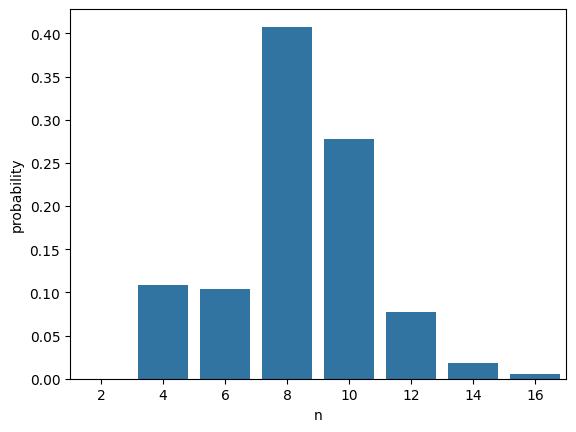

In [2]:
N = 16
temperature = 300  # Kelvin
pressure = 1  # bar
steps = 1e4
time = 10
diffusion = True  # Set to False to disable diffusion
particle_size = 300  # nm
c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

C2_conc, C2_out_conc = c2_model.predict_absolute(np.array([pressure * 101325]), 
                                                 np.array([temperature])), \
                    c2_model.predict_out(np.array([pressure * 101325]), 
                                         np.array([temperature]))

energy_barriers = EnergyBarriersSimplifyed(
    temperature=temperature,
    pressure=pressure
)

reactor = ReactorStream(
    N=N,
    T=temperature,
    pressure=pressure,
    L=particle_size,
    time_hours=time,
    n_steps=int(steps),
    diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
    ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
    energy_model=energy_barriers,
    initial_concs={'CatC2(C2)': 1e-2, 'C2': C2_conc[0], 'C2_out': C2_out_conc[0]},
    include_diffusion=diffusion
)


reactor.solver = reactor._build_solver()

def max_constant(reactions):
    return np.max([i[1:] for i in reactions])

def normilize_constants(reactions, r_max=1e6):
    factor = r_max/max_constant(reactions)
    if factor >=1:
        factor = 1
    for i in range(len(reactions)):
        reactions[i] = (reactions[i][0], reactions[i][1] * factor, reactions[i][2] * factor)
    return factor

def remove_back_ins(reactions, N):
    number_of_insertions = N//2 - 2
    for cnt, i in enumerate(reactions):
        if cnt > number_of_insertions:
            break
        reactions[cnt] = (i[0].replace('<->', '->'), i[1], i[2])

def slowdawn_back_ins(reactions, N, order):
    number_of_insertions = N//2 - 2
    for cnt, i in enumerate(reactions):
        if cnt > number_of_insertions:
            break
        reactions[cnt] = (i[0], i[1], i[2]*10**(-order))

def check_errors(ts):
    return all(ts.min() > -1e-2)

factor = normilize_constants(reactor._reactions, r_max=1e6)
# remove_back_ins(reactor._reactions, reactor.N)
# slowdawn_back_ins(reactor._reactions, reactor.N, order=8)
reactor.time_hours /= factor

for i in reactor._reactions:
    print('{:35s} {:5.2e} {:5.2e}'.format(*i))

distr, ts = reactor.run(build_solver=False)

sns.barplot(data=distr, x='n', y='probability')
check_convergance(ts, error_threshold=1e-6)
np.round(np.sum(distr.n * distr.probability))

## Generate data

In [3]:
import os
import tqdm
import warnings
from IPython.display import clear_output
from func_timeout import func_timeout, FunctionTimedOut
from itertools import product
from joblib import Parallel, delayed
from tqdm_joblib import tqdm_joblib
from joblib import Parallel, delayed
from tqdm.auto import tqdm
import numpy as np
import os


c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

def get_distr(N, temperature, pressure, steps, time, diffusion, stream, ps, cat_conc, is_remove_back_ins=False):
    C2_conc, C2_out_conc = c2_model.predict_absolute(np.array([pressure * 101325]), 
                                                 np.array([temperature])), \
                    c2_model.predict_out(np.array([pressure * 101325]), 
                                         np.array([temperature]))


    energy_barriers = EnergyBarriersSimplifyed(
        temperature=temperature,
        pressure=pressure
    )

    reactor_model = ReactorStream if stream else ReactorSimulationChemisorptionSimplified
    reactor = reactor_model(
        N=N,
        T=temperature,
        pressure=pressure,
        L=ps,
        time_hours=time,
        n_steps=int(steps),
        diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
        ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
        energy_model=energy_barriers,
        initial_concs={'CatC2(C2)': cat_conc, 'C2': C2_conc[0], 'C2_out': C2_out_conc[0]},
        include_diffusion=diffusion
    )
    
    reactor.solver = reactor._build_solver()
    norm_factor = normilize_constants(reactor._reactions, r_max=1e6)
    reactor.time_hours /= norm_factor
    if is_remove_back_ins:
        remove_back_ins(reactor._reactions, reactor.N)
    distr, ts = reactor.run(build_solver=False)
    ts.index = ts.index * norm_factor
    return distr, ts

# --- helper that runs INSIDE the timed worker and captures warnings there ---
def _get_distr_capture_warnings(args_tuple):
    import warnings
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", category=Warning)
        distr, ts = get_distr(*args_tuple)  # must return (distr, ts)
    had_warnings = any(issubclass(msg.category, Warning) for msg in w)
    return distr, ts, had_warnings

N = 16
df = pd.DataFrame()
steps = 1e3
time = 10
temperatures = np.linspace(300, 600, 21)
pressures = np.linspace(1, 50, 11)

diffusion_modes = (True,)#(True, False)
stream_modes = (False,)#(True, False)
particle_sizes = (1000,) #(50, 300, 1000, 10000)
cat_concentration = (1e-2,)#(1e-2, 1e-1, 1e-3)
waiting_time = 30  # seconds
output_folder = 'files/modeling_C16_10h_noback/'
is_remove_back_ins = True
# --- Build task list (skip those already on disk) ---
def make_tail(temperature, pressure, N, diffusion, stream, ps, cat_conc):
    return f"temperature_{temperature}_pressure_{pressure}_N_{N}_diffusion_{diffusion}_stream_{stream}_particleSize_{ps}_cat_conc_{cat_conc}"

all_tasks = []
for temperature, ps, pressure, diffusion, stream, cat_conc in product(
        temperatures, particle_sizes, pressures, diffusion_modes, stream_modes, cat_concentration):
    if (not diffusion) and stream:
        continue
    tail = make_tail(temperature, pressure, N, diffusion, stream, ps, cat_conc)
    out_d = f"{output_folder}/distr_{tail}.pkl"
    out_t = f"{output_folder}/ts_{tail}.pkl"
    if os.path.exists(out_d):
        continue
    all_tasks.append((temperature, ps, pressure, diffusion, stream, cat_conc, is_remove_back_ins, tail))

print(f"Queued {len(all_tasks)} tasks")



# --- Worker: identical logic to your serial loop for one (T,ps,p,diff,stream,cat) ---
def run_one_task(task):
    temperature, ps, pressure, diffusion, stream, cat_conc, is_remove_back_ins, tail = task
    try:
        ok = False
        for time_increase in range(1):
            
            try:
                # grow total simulation time geometrically
                ttry = time * (10 ** time_increase)
                
                distr, ts, had_warnings = func_timeout(
                    waiting_time,
                    _get_distr_capture_warnings,
                    args=((N, temperature, pressure, steps, ttry, diffusion, stream, ps, cat_conc, is_remove_back_ins),)
                )

                had_warnings = not check_errors(ts)
                # any warning -> try longer ttry
                if had_warnings:
                     return {"tail": tail, "status": "skipped_errors"}
                # accept only if converged and warning-free
                if True:#check_convergance(ts, error_threshold=1e6):
                    ok = True
                    break
            except FunctionTimedOut:
                # ran longer than waiting_time -> try next (longer ttry)
                continue
            except Exception:
                # any error -> try next attempt
                continue
        
        if not ok:
            return {"tail": tail, "status": "skipped_no_convergence"}

        # write outputs (unique filenames -> safe in parallel)
        os.makedirs(output_folder, exist_ok=True)
        distr.to_pickle(f"{output_folder}/distr_{tail}.pkl")
        ts.to_pickle(f"{output_folder}/ts_{tail}.pkl")
        return {"tail": tail, "status": "ok"}

    except Exception as e:
        return {"tail": tail, "status": "error", "error": str(e)}


# run_one_task(all_tasks[0])

Queued 231 tasks


/home/aleksandr/miniconda3/envs/kinetic_model/lib/python3.12/site-packages/tqdm_joblib/__init__.py:4: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


In [4]:
with tqdm_joblib(tqdm(total=len(all_tasks), desc="Simulating conditions")) as progress_bar:
    results = Parallel(n_jobs=-1, backend="loky", pre_dispatch="2*n_jobs")(
        delayed(run_one_task)(t) for t in all_tasks
    )


# (optional) quick summary
ok_cnt  = sum(r["status"]=="ok" for r in results)
skp_cnt = sum(r["status"]=="skipped_no_convergence" for r in results)
err_cnt = sum(r["status"]=="error" for r in results)
print(f"Done. ok={ok_cnt}, skipped={skp_cnt}, errors={err_cnt}")

100%|██████████| 231/231 [00:10<00:00, 23.05it/s]:00<?, ?it/s]

Done. ok=229, skipped=2, errors=0
